Coming up with a 'best' Pittsburgh neighborhood has a lot of implications depending on what you want out of a good neighborhood. The first thing that comes to mind might be what is the best to live in personally, but statistically more people are going to visit Pittsburgh than live there. So, one way of looking at the "best" neighborhood would be to see which is the most accessible and easy to get around, even when you don't have a car.

So, a good metric for determining the "best" neighborhood in Pittsburgh is the amount of pedestrian transportation available.

To find this metric, we will investigate features pulled from 3 datasets:
- POGOH Stations
- PRT Stops
- Sidewalk to Street "Walkability" Ratio

Data for POGOH stations was taken from the May 2026 update of the POGOH Station Locations dataset at https://data.wprdc.org/datastore/dump/e90f2fca-dd24-47bc-b2ce-307a3579dab9?bom=True.

Categorizing the stations' latitude and longitude into Pittsburgh neighborhoods (and removing the neighborhoods with less than 2 racks for a more readable chart) gives us the following:

In [1]:
import geopandas
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point

# Load zip codes
ZIPS = geopandas.read_file("https://data.wprdc.org/dataset/1a5135de-cabe-4e23-b5e4-b2b8dd733817/resource/ec228c0e-6b1e-4f44-a335-df05546d52ea/download/alcogisallegheny-county-zip-code-boundaries.zip")

# Load neighborhoods and use zip codes to convert
NEIGHBORHOODS = geopandas.read_file("https://data.wprdc.org/dataset/e672f13d-71c4-4a66-8f38-710e75ed80a4/resource/c5a93a8e-03d7-4eb3-91a8-c6b7db0fa261/download/pittsburghpaneighborhoods-.zip").to_crs(ZIPS.crs)

def get_neighborhood(row):
    # Create a shapely point for the latitude and longitude
    pt = Point(row["Longitude"], row["Latitude"])
    ptg = geopandas.GeoDataFrame(geometry=[pt], crs="EPSG:4326").to_crs(NEIGHBORHOODS.crs)
    # Loop through the neighborhoods
    for _idx, neighborhood in NEIGHBORHOODS.iterrows():
        # Check if this neighborhood contains the point
        if neighborhood["geometry"].contains(ptg.geometry.iloc[0]):
            # Return the name of the neighborhood
            return neighborhood["hood"]
    # Wasn't contained in the neighborhood
    return None

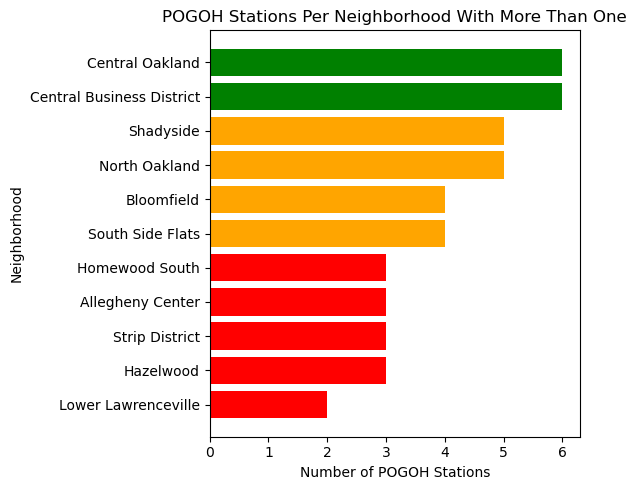

In [3]:
racks = pd.read_csv("pogohstation.csv")

racks["neighborhood"] = racks.apply(get_neighborhood, axis=1)

racks_by_neighborhood = racks.groupby("neighborhood").size().reset_index(name="num_racks").sort_values(by="num_racks", ascending=False)

neighborhoods_with_racks = racks_by_neighborhood.query("num_racks > 1")

plt.figure(figsize=(6,5))
color = ["green" if x>5 else "orange" if x>3 else "red" for x in neighborhoods_with_racks["num_racks"]]
plt.barh(neighborhoods_with_racks["neighborhood"], neighborhoods_with_racks["num_racks"], color=color)
plt.xlabel("Number of POGOH Stations")
plt.ylabel("Neighborhood")
plt.title("POGOH Stations Per Neighborhood With More Than One")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()

Here we can see that few neighborhoods have more than 1 station, and neighborhoods like Central Oakland and the Central Business District have a staggering 6. Many more neighborhoods have just one or two in comparison.

Next, data for PRT stops was pulled from the current stops dataset on the PRT's data portal, available at https://data.wprdc.org/dataset/33d5f44b-5315-4374-b3e3-e4246e8ad5c9/resource/0a26e18e-f78b-43d2-8c75-2498ae255ecf/download/stopsdatadictionary.csv.

Categorizing the stations' latitude and longitude into Pittsburgh neighborhoods gives us the following:

[PUT ANALYSIS HERE]

Finally, data for the walkability ratio was pulled from the 2021 walkability survey available at https://data.wprdc.org/dataset/853a077d-0a31-4292-8a1d-5d60b530169b/resource/ab8db07e-09ef-45c4-bad2-f7d32bfc5f26/download/sidewalkstreetratiotract.csv.

Categorizing the census tract of each ratio into Pittsburgh neighborhoods gives us the following:

[PUT ANALYSIS HERE]

By normalizing each of the three features into ratios and adding each ratio together, we obtain data for our final metric, the amount of pedestrian transportation available per neighborhood.

[PUT ANALYSIS HERE]

[MATTHEW CONCLUSION]

[ALEX CONCLUSION]

[DOM CONCLUSION]